# <center>Healthcare Analytics for Doctor Visits

## VOIS TIRTC AICTE Data Analytics DIY Project - 2026
- **Domain:** Healthcare
- **Theme:** Doctor Visits Analytics
- **Tools:** Python (Jupyter Notebook environment), Pandas, NumPy, Matplotlib, Seaborn
- **Prepared by:** SANTHOSHA J
- **STU ID:** STU6903150a9baac1761809674
- **Internship ID:** INTERNSHIP_17830691666a4779eecfe8a

## 1. Problem Statement:
The Doctor Visits dataset contains information about individuals' doctor visits, demographic characteristics, income, illness, health status, chronic conditions, and healthcare coverage. The objective is to explore the dataset and identify patterns and relationships between these factors and the frequency of doctor visits. The analysis will focus on understanding how demographic, health-related, and healthcare-access factors are associated with doctor visit patterns.

## 2. Project Objectives:
- Perform data cleaning and quality assessment to ensure the dataset is suitable for analysis.
- Understand the distribution and characteristics of doctor visits.
- Analyse the relationship between demographic factors such as age, gender, and income and doctor visits.
- Examine how illness, reduced activity, and health status are associated with doctor visits.
- Investigate the relationship between chronic conditions and doctor visit frequency.
- Explore whether healthcare coverage and support are associated with differences in doctor visits.
- Identify key patterns, trends, and insights through statistical and visual analysis.
- Summarise the findings into clear, evidence-based conclusions.

## 3. Introduction to the Dataset:
The Doctor Visits dataset consists of 5,190 observations describing individuals' doctor visits, demographic characteristics, health conditions, income, and healthcare coverage. 

Since the provided dataset did not include a separate data dictionary, the variable definitions and measurement scales were verified using the publicly available documentation of the original DoctorVisits dataset.

The dataset originates from the 1977–1978 Australian Health Survey. The primary variable, visits, represents the number of doctor visits during the previous two weeks. The EDA aims to identify patterns and relationships between doctor visits and demographic, health-related, and healthcare-access factors.

**Dataset file:** `1776250375-P2-Healthcare Analytics for Doctor Visits.csv`

**Original Dataset Documentation:** [DoctorVisits Dataset Documentation](https://vincentarelbundock.github.io/Rdatasets/doc/AER/DoctorVisits.html)

## 4. Importing Essential Libraries & Data Loading:

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Loading the data
doc_visit_data = pd.read_csv("1776250375-P2-Healthcare Analytics for Doctor Visits.csv")

print("Dataset loaded successfully")

Dataset loaded successfully


## 5. Dataset overview:

In [3]:
# Size of the data
print(doc_visit_data.shape)

print("Number of rows:", doc_visit_data.shape[0])
print("Number of columns:", doc_visit_data.shape[1])

(5190, 13)
Number of rows: 5190
Number of columns: 13


In [4]:
doc_visit_data.head()  # first 5 rows

,Unnamed: 0,visits,gender,age,income,illness,reduced,health,private,freepoor,freerepat,nchronic,lchronic
0,1,1,female,0.19,0.55,1,4,1,yes,no,no,no,no
1,2,1,female,0.19,0.45,1,2,1,yes,no,no,no,no
2,3,1,male,0.19,0.90,3,0,0,no,no,no,no,no
3,4,1,male,0.19,0.15,1,0,0,no,no,no,no,no
4,5,1,male,0.19,0.45,2,5,1,no,no,no,yes,no


In [5]:
doc_visit_data.tail()  # last 5 rows

,Unnamed: 0,visits,gender,age,income,illness,reduced,health,private,freepoor,freerepat,nchronic,lchronic
5185,5186,0,female,0.22,0.55,0,0,0,no,no,no,no,no
5186,5187,0,male,0.27,1.30,0,0,1,no,no,no,no,no
5187,5188,0,female,0.37,0.25,1,0,1,no,no,yes,no,no
5188,5189,0,female,0.52,0.65,0,0,0,no,no,no,no,no
5189,5190,0,male,0.72,0.25,0,0,0,no,no,yes,no,no


In [6]:
doc_visit_data.columns

Index(['Unnamed: 0', 'visits', 'gender', 'age', 'income', 'illness', 'reduced',
       'health', 'private', 'freepoor', 'freerepat', 'nchronic', 'lchronic'],
      dtype='object')

In [7]:
doc_visit_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5190 entries, 0 to 5189
Data columns (total 13 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  5190 non-null   int64  
 1   visits      5190 non-null   int64  
 2   gender      5190 non-null   object 
 3   age         5190 non-null   float64
 4   income      5190 non-null   float64
 5   illness     5190 non-null   int64  
 6   reduced     5190 non-null   int64  
 7   health      5190 non-null   int64  
 8   private     5190 non-null   object 
 9   freepoor    5190 non-null   object 
 10  freerepat   5190 non-null   object 
 11  nchronic    5190 non-null   object 
 12  lchronic    5190 non-null   object 
dtypes: float64(2), int64(5), object(6)
memory usage: 527.2+ KB


In [8]:
# Checking statistical features of the data (only for numeric columns)
doc_visit_data.describe().T

,count,mean,std,min,25%,50%,75%,max
Unnamed: 0,5190.0,2595.500000,1498.368279,1.00,1298.25,2595.50,3892.75,5190.00
visits,5190.0,0.301734,0.798134,0.00,0.00,0.00,0.00,9.00
age,5190.0,0.406385,0.204782,0.19,0.22,0.32,0.62,0.72
income,5190.0,0.583160,0.368907,0.00,0.25,0.55,0.90,1.50
illness,5190.0,1.431985,1.384152,0.00,0.00,1.00,2.00,5.00
reduced,5190.0,0.861850,2.887628,0.00,0.00,0.00,0.00,14.00
health,5190.0,1.217534,2.124266,0.00,0.00,0.00,2.00,12.00


In [9]:
# Categorical column's overview
doc_visit_data.describe(include="object").T

,count,unique,top,freq
gender,5190,2,female,2702
private,5190,2,no,2892
freepoor,5190,2,no,4968
freerepat,5190,2,no,4099
nchronic,5190,2,no,3098
lchronic,5190,2,no,4585


In [10]:
# Column-wise Number of unique values
doc_visit_data.nunique().sort_values()

gender           2
private          2
freepoor         2
freerepat        2
nchronic         2
lchronic         2
illness          6
visits          10
age             12
health          13
income          14
reduced         15
Unnamed: 0    5190
dtype: int64

## 6. Data quality assessment & Data Cleaning:

### 6.1 Checking Missing Values / Null Values:

In [11]:
# Checking missing values in each column
doc_visit_data.isnull().sum()

Unnamed: 0    0
visits        0
gender        0
age           0
income        0
illness       0
reduced       0
health        0
private       0
freepoor      0
freerepat     0
nchronic      0
lchronic      0
dtype: int64

- **No missing values were found in any of the columns. Therefore, no missing-value imputation or row deletion was required.**

### 6.2 Checking duplicate rows:

In [12]:
# Check exact duplicate rows
print("Duplicate rows:", doc_visit_data.duplicated().sum())

Duplicate rows: 0


- **No duplicate records were identified in the dataset.**

### 6.3 Data Transformation:
- The `age` and `income` variables were stored in scaled units in the original dataset.
- According to the original dataset documentation, `age` is represented as **age in years divided by 100**, while `income` is represented in **units of $10,000**.
- For easier interpretation during analysis and visualisation, corresponding `age_years` and `income_dollars` variables were created. The original variables were retained to preserve the source data.

In [13]:
# Convert age to years
doc_visit_data['age_years'] = doc_visit_data['age'] * 100

# Convert income to dollars
doc_visit_data['income_dollars'] = doc_visit_data['income'] * 10000

In [14]:
# Verifying the transformation 

print("Age conversion:")
display(
    doc_visit_data[['age', 'age_years']].drop_duplicates().sort_values('age')
)

print("\nIncome conversion:")
display(
    doc_visit_data[['income', 'income_dollars']].drop_duplicates().sort_values('income')
)

Age conversion:


,age,age_years
0,0.19,19.0
114,0.22,22.0
288,0.27,27.0
375,0.32,32.0
425,0.37,37.0
451,0.42,42.0
473,0.47,47.0
503,0.52,52.0
557,0.57,57.0
629,0.62,62.0



Income conversion:


,income,income_dollars
27,0.00,0.0
65,0.01,100.0
33,0.06,600.0
3,0.15,1500.0
11,0.25,2500.0
5,0.35,3500.0
1,0.45,4500.0
0,0.55,5500.0
8,0.65,6500.0
39,0.75,7500.0


In [15]:
# Final data summary after cleaning

print("Rows:", doc_visit_data.shape[0])
print("Columns:", doc_visit_data.shape[1])

print("\nMissing values:", doc_visit_data.isnull().sum().sum())

print("\nDuplicate rows:", doc_visit_data.duplicated().sum())

print("\nData Information:")
doc_visit_data.info()

Rows: 5190
Columns: 15

Missing values: 0

Duplicate rows: 0

Data Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5190 entries, 0 to 5189
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Unnamed: 0      5190 non-null   int64  
 1   visits          5190 non-null   int64  
 2   gender          5190 non-null   object 
 3   age             5190 non-null   float64
 4   income          5190 non-null   float64
 5   illness         5190 non-null   int64  
 6   reduced         5190 non-null   int64  
 7   health          5190 non-null   int64  
 8   private         5190 non-null   object 
 9   freepoor        5190 non-null   object 
 10  freerepat       5190 non-null   object 
 11  nchronic        5190 non-null   object 
 12  lchronic        5190 non-null   object 
 13  age_years       5190 non-null   float64
 14  income_dollars  5190 non-null   float64
dtypes: float64(4), int64(5), object(6)
memory u

### Data Quality & Cleaning Insights:
- The dataset contains **5,190 records and 13 original columns**.

- The `Unnamed: 0` column contains sequential record identifiers and was retained in its original form. It is not considered an analytical variable.

- The dataset contains **no missing values**, so no missing-value imputation or record deletion was required.

- The dataset contains **no exact duplicate rows** based on the complete records, including the record identifier.

- Different individuals may have identical demographic or health characteristics. Therefore, records with the same values across analytical columns were not automatically treated as duplicates.

- The original `age` and `income` variables are stored in scaled formats. Derived variables `age_years` and `income_dollars` were created for easier interpretation while preserving the original columns.

## 7. Target Variable Analysis — `visits`

In [16]:
# Basic statistics for 'visits'
doc_visit_data['visits'].describe()

count    5190.000000
mean        0.301734
std         0.798134
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max         9.000000
Name: visits, dtype: float64

In [17]:
# Frequency of doctor visits
visit_counts = doc_visit_data['visits'].value_counts().sort_index()

# Percentage distribution of visits
visit_percentage = doc_visit_data['visits'].value_counts(normalize=True).sort_index() * 100

visit_summary = pd.DataFrame({
    'Count': visit_counts,
    'Percentage': visit_percentage.round(2)
})

print(visit_summary)

        Count  Percentage
visits                   
0        4141       79.79
1         782       15.07
2         174        3.35
3          30        0.58
4          24        0.46
5           9        0.17
6          12        0.23
7          12        0.23
8           5        0.10
9           1        0.02


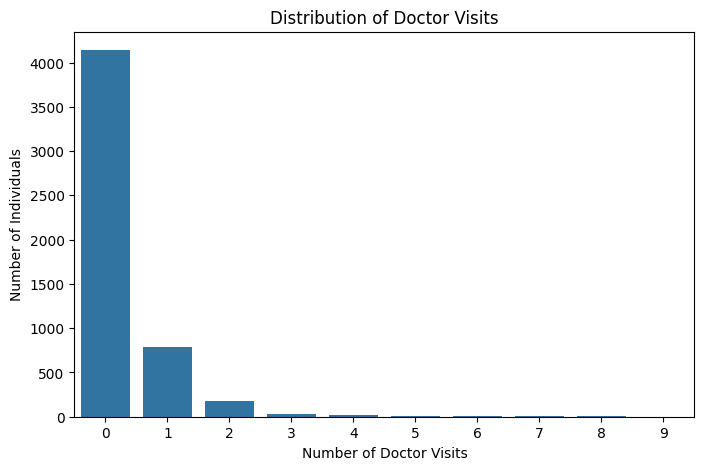

In [18]:
# Visualise distribution

plt.figure(figsize=(8, 5))

sns.countplot(data=doc_visit_data, x='visits')

plt.title('Distribution of Doctor Visits')
plt.xlabel('Number of Doctor Visits')
plt.ylabel('Number of Individuals')
plt.show()

In [19]:
# Creating a 'visited_doctor' column indicating whether an individual visited a doctor at least once
doc_visit_data['visited_doctor'] = np.where(doc_visit_data['visits'] > 0, 'Yes', 'No')

# Frequency distribution of doctor visit status
doc_visit_data['visited_doctor'].value_counts()

visited_doctor
No     4141
Yes    1049
Name: count, dtype: int64

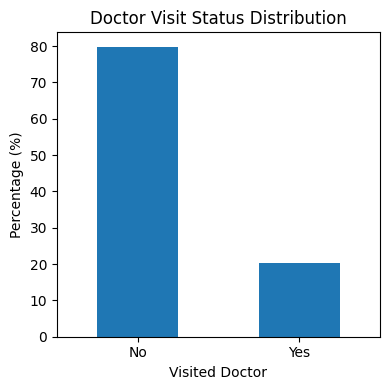

In [20]:
# Doctor Visit Status Percentage Distribution

Doctor_Visit_Status_Perc = doc_visit_data['visited_doctor'].value_counts(normalize=True) * 100

Doctor_Visit_Status_Perc.plot(kind='bar', figsize=(4, 4))

plt.title('Doctor Visit Status Distribution')
plt.xlabel('Visited Doctor')
plt.ylabel('Percentage (%)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Target Variable Analysis — Key Insights

- The `visits` variable ranges from **0 to 9** across **5,190 observations**, representing the number of doctor visits per individual.

- **79.79%** of individuals had **no doctor visits**, while **15.07% had one visit**. Together, **94.86% had either 0 or 1 visit**, showing a strong concentration at the lower end.

- The 25th, 50th (median), and 75th percentiles are all 0, confirming that **at least 75% of individuals had no doctor visits**.

- The mean number of visits is **0.30**, compared with a median of **0**, indicating that the small proportion of individuals with multiple visits raises the average above the typical observed value.

- The distribution is **strongly right-skewed**, with most observations at zero and progressively fewer individuals at higher visit counts, extending up to 9.

- When converted into the binary variable `visited_doctor`, **4,141 individuals (79.79%)** fall into **“No”**, while **1,049 (20.21%)** fall into **“Yes”**. Thus, approximately **1 in 5 individuals visited a doctor at least once**.

- The binary target is **imbalanced**, with nearly four times as many “No” observations as “Yes” observations. This should be considered when evaluating classification models, particularly their ability to identify individuals who visited a doctor.

- Overall, `visits` has a **zero-heavy, right-skewed count distribution**, while `visited_doctor` has an **imbalanced binary distribution**. These characteristics are important for subsequent EDA and model evaluation.

## 8. Univariate Analysis

### 8.1 Demographic Variables Analysis:

#### Gender:

In [21]:
# Gender Distribution
doc_visit_data['gender'].value_counts()

gender
female    2702
male      2488
Name: count, dtype: int64

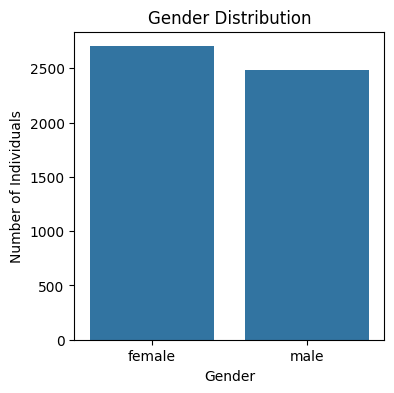

In [22]:
# Visualise Gender Distribution

plt.figure(figsize=(4, 4))

sns.countplot(data= doc_visit_data, x= 'gender')

plt.title('Gender Distribution')
plt.xlabel('Gender')
plt.ylabel('Number of Individuals')
plt.show()

#### Age:

In [23]:
# Age Distribution
doc_visit_data['age_years'].value_counts().sort_index()

age_years
19.0     752
22.0    1213
27.0     523
32.0     301
37.0     146
42.0     126
47.0     181
52.0     222
57.0     273
62.0     316
67.0     315
72.0     822
Name: count, dtype: int64

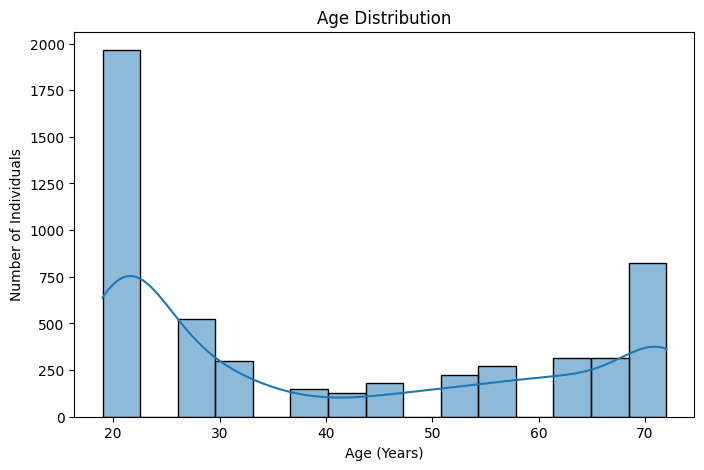

In [24]:
# Visualise Age Distribution

plt.figure(figsize=(8, 5))

sns.histplot(data=doc_visit_data, x='age_years', bins=15, kde=True)

plt.title('Age Distribution')
plt.xlabel('Age (Years)')
plt.ylabel('Number of Individuals')
plt.show()

#### Income:

In [25]:
# Income Distribution
doc_visit_data['income_dollars'].value_counts().sort_index()

income_dollars
0.0          79
100.0        35
600.0        80
1500.0      249
2500.0     1195
3500.0      462
4500.0      400
5500.0      467
6500.0      455
7500.0      441
9000.0      589
11000.0     361
13000.0     162
15000.0     215
Name: count, dtype: int64

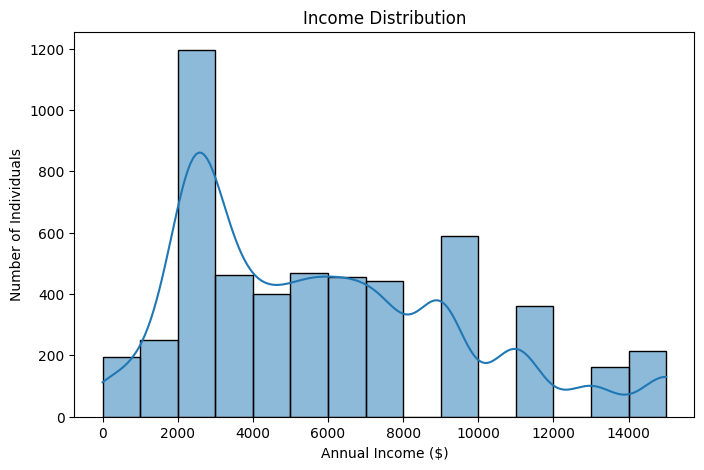

In [26]:
# Visualising Income Distribution

plt.figure(figsize=(8, 5))

sns.histplot(data=doc_visit_data, x='income_dollars', bins=15, kde=True)

plt.title('Income Distribution')
plt.xlabel('Annual Income ($)')
plt.ylabel('Number of Individuals')
plt.show()

### Demographic Analysis — Key Insights

#### Gender:
- The dataset has a **fairly balanced gender distribution**, with **2,702 females** and **2,488 males**.
- Females represent approximately **52.1%** and males **47.9%**, so there is no substantial gender imbalance in the dataset.

#### Age:
- Age ranges from approximately **19 to 72 years**, covering both younger and older adult groups.
- The distribution is **not uniform**: individuals aged around **22 years form the largest group (1,213)**, followed by those around **72 years (822)**.
- The relatively lower frequencies in the middle-age groups and higher frequencies at the younger and older ends indicate a **non-uniform, somewhat U-shaped distribution**.
- This age pattern should be considered when examining the relationship between age and doctor visits, as different age groups may have different visit patterns.

#### Income:
- Annual income ranges from **0 to 15,000 dollars**, with observations spread across the range.
- The highest concentration occurs around **2,500 dollars (1,195 individuals)**, making it the most common income level.
- Income is **unevenly distributed**, with fewer individuals at the higher income levels and a noticeable decline after approximately **9,000–11,000 dollars**.
- A small number of individuals have **very low or zero income**, while higher-income observations extend up to 15,000 dollars, indicating a relatively wide income range.

#### Overall Demographic Insight:
- Overall, **gender is relatively balanced**, while **age and income show more pronounced distributional differences**. These demographic characteristics provide important context for subsequent analysis of factors associated with doctor visits.

### 8.2 Health & Illness Analysis: 

#### Illness:

In [27]:
# Illness Distribution
doc_visit_data['illness'].value_counts().sort_index()

illness
0    1554
1    1638
2     946
3     542
4     274
5     236
Name: count, dtype: int64

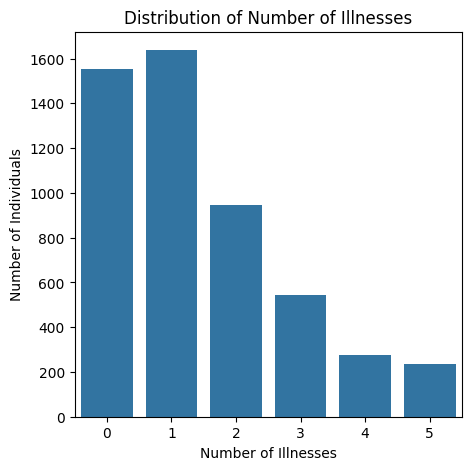

In [28]:
# Visualising Illness Distribution

plt.figure(figsize=(5, 5))

sns.countplot(data=doc_visit_data, x='illness')

plt.title('Distribution of Number of Illnesses')
plt.xlabel('Number of Illnesses')
plt.ylabel('Number of Individuals')
plt.show()

#### Reduced activity:

In [29]:
# Reduced Activity Distribution
doc_visit_data['reduced'].value_counts().sort_index()

reduced
0     4454
1      177
2      108
3       74
4       45
5       40
6       17
7       38
8       17
9        7
10      12
11       2
12       6
13       5
14     188
Name: count, dtype: int64

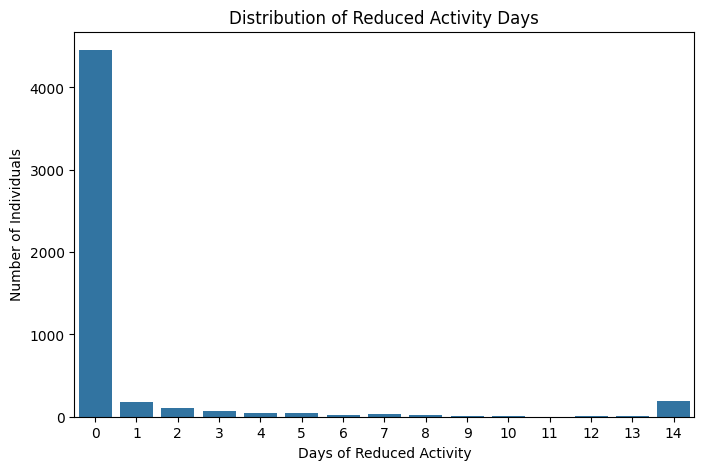

In [30]:
# Visualising Reduced Activity Distribution

plt.figure(figsize=(8, 5))

sns.countplot(data=doc_visit_data, x='reduced')

plt.title('Distribution of Reduced Activity Days')
plt.xlabel('Days of Reduced Activity')
plt.ylabel('Number of Individuals')
plt.show()

#### Health score:

In [31]:
# Health Status Score Distribution
doc_visit_data['health'].value_counts().sort_index()

health
0     3026
1      823
2      446
3      273
4      187
5      132
6      104
7       61
8       42
9       32
10      21
11      24
12      19
Name: count, dtype: int64

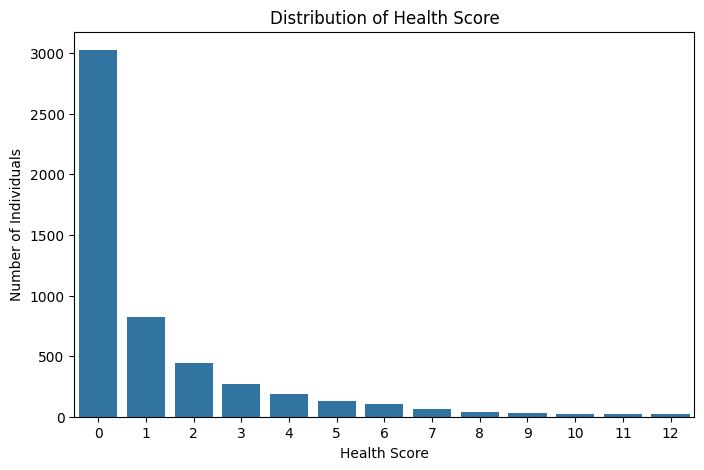

In [32]:
# Health Status Score Distribution Visualisation

plt.figure(figsize=(8, 5))

sns.countplot(data=doc_visit_data, x='health')

plt.title('Distribution of Health Score')
plt.xlabel('Health Score')
plt.ylabel('Number of Individuals')
plt.show()

#### Chronic Condition:

In [33]:
# Non-Limiting Chronic Condition Distribution
doc_visit_data['nchronic'].value_counts()

nchronic
no     3098
yes    2092
Name: count, dtype: int64

In [34]:
# Activity-Limiting Chronic Condition Distribution
doc_visit_data['lchronic'].value_counts()

lchronic
no     4585
yes     605
Name: count, dtype: int64

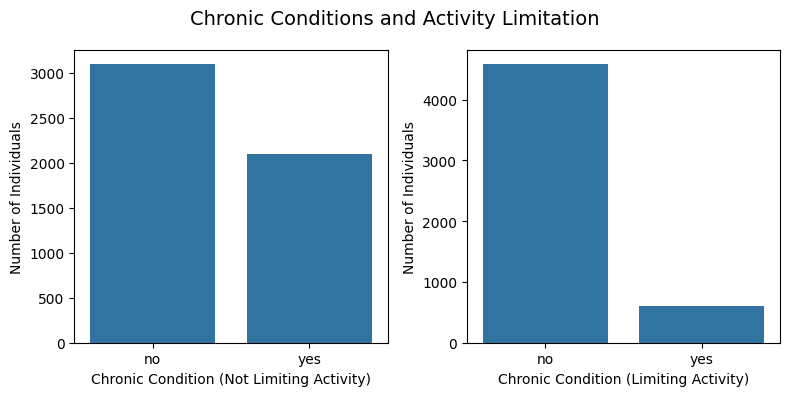

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
fig.suptitle('Chronic Conditions and Activity Limitation', fontsize=14)

# Non-limiting chronic condition
sns.countplot(data=doc_visit_data, x='nchronic', ax=axes[0])

axes[0].set_xlabel('Chronic Condition (Not Limiting Activity)')
axes[0].set_ylabel('Number of Individuals')

# Activity-limiting chronic condition
sns.countplot(data=doc_visit_data, x='lchronic', ax=axes[1])

axes[1].set_xlabel('Chronic Condition (Limiting Activity)')
axes[1].set_ylabel('Number of Individuals')

plt.tight_layout()
plt.show()

### Health & Illness Analysis — Key Insights

- **Illness count ranges from 0 to 5**, with the highest frequency at **1 illness (1,638 individuals)**, followed by **0 illnesses (1,554)**.

- Most individuals have **0 or 1 illness**, accounting for approximately **61.5% of the dataset**, while the frequency declines steadily as the number of illnesses increases.

- Only **274 individuals (5.3%) have 4 illnesses** and **236 (4.5%) have 5 illnesses**, showing that higher illness counts are relatively uncommon.

- **Reduced activity days are heavily concentrated at 0 days**: **4,454 individuals (85.8%)** reported no reduced-activity days. The remaining observations are spread across 1–14 days, with **14 days (188 individuals)** forming a noticeable secondary concentration.

- The `reduced` variable therefore shows a **strongly right-skewed distribution**, with most individuals experiencing no reduced activity and relatively few reporting multiple days.

- **Health score is also strongly concentrated at 0**: **3,026 individuals (58.3%)** have a health score of 0, after which the frequency decreases consistently as the score increases up to 12.

- Overall, the health-related variables show **high concentration at lower values and declining frequencies at higher values**, particularly for reduced activity and health score. This indicates substantial variation in health-related conditions across individuals and provides important variables for examining differences in doctor visits.

- **Non-limiting chronic conditions are relatively common**: **2,092 individuals (40.3%)** have at least one non-limiting chronic condition, while **59.7%** do not.

- **Activity-limiting chronic conditions are much less common**: only **605 individuals (11.7%)** have such a condition, while **88.3%** do not.

- The large difference between the two categories suggests that **chronic conditions that do not restrict daily activity are considerably more prevalent than conditions that limit activity**.

- Overall, the data indicates that **chronic health conditions are present in a substantial portion of the population**, but only a smaller proportion experience conditions severe enough to limit their usual activities.

### 8.3 Healthcare Access Analysis:

#### Private Health Insurance:

In [36]:
# Private Insurance Coverage Distribution
doc_visit_data['private'].value_counts()

private
no     2892
yes    2298
Name: count, dtype: int64

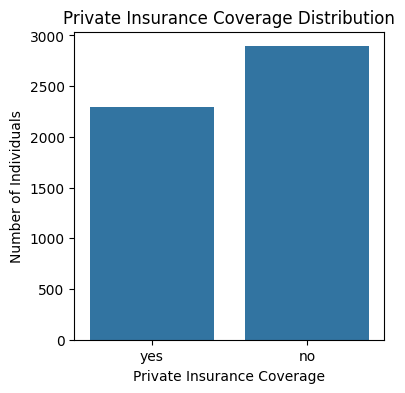

In [37]:
# Private Insurance Coverage Distribution Visualisation

plt.figure(figsize=(4, 4))

sns.countplot(data=doc_visit_data, x='private')

plt.title('Private Insurance Coverage Distribution')
plt.xlabel('Private Insurance Coverage')
plt.ylabel('Number of Individuals')
plt.show()

#### Free Healthcare:

In [38]:
# Free Government Health Insurance Due to Low Income
doc_visit_data['freepoor'].value_counts()

freepoor
no     4968
yes     222
Name: count, dtype: int64

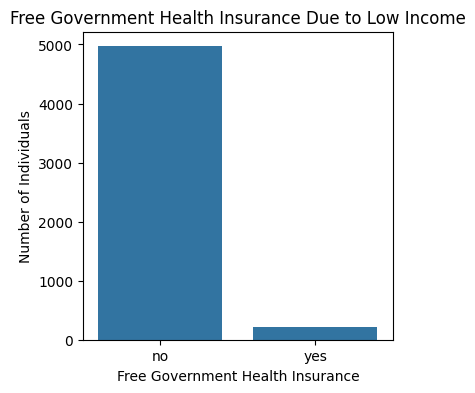

In [39]:
# Visualisation

plt.figure(figsize=(4, 4))

sns.countplot(data=doc_visit_data, x='freepoor')

plt.title('Free Government Health Insurance Due to Low Income')
plt.xlabel('Free Government Health Insurance')
plt.ylabel('Number of Individuals')
plt.show()

#### Repatriation Support:

In [40]:
# Free Government Health Insurance Due to Old Age, Disability, or Veteran Status
doc_visit_data['freerepat'].value_counts()

freerepat
no     4099
yes    1091
Name: count, dtype: int64

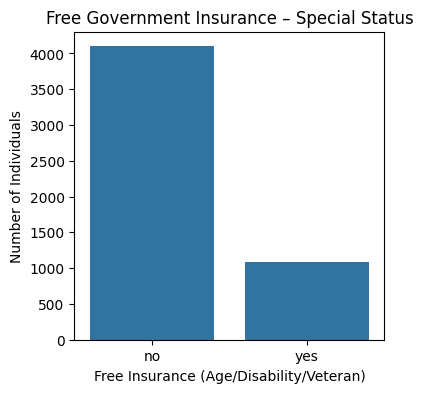

In [41]:
# Visualisation

plt.figure(figsize=(4, 4))

sns.countplot(data=doc_visit_data, x='freerepat')

plt.title('Free Government Insurance – Special Status')
plt.xlabel('Free Insurance (Age/Disability/Veteran)')
plt.ylabel('Number of Individuals')
plt.show()

### Healthcare Access Analysis — Key Insights

- **Private insurance coverage is relatively balanced**: **2,892 individuals (55.7%)** do not have private insurance, while **2,298 (44.3%)** have coverage.

- **Free government insurance due to low income is uncommon**: only **222 individuals (4.3%)** have this coverage, while **95.7%** do not.

- **Free government insurance due to old age, disability, or veteran status is more common**, with **1,091 individuals (21.0%)** covered and **4,099 (79.0%)** not covered.

- Comparing the government insurance variables, **special-status coverage (age/disability/veteran) is substantially more prevalent than low-income-based coverage**, indicating different levels of representation across these healthcare access categories.

- Overall, the dataset contains a **mix of privately insured and government-insured individuals**, but **most individuals do not receive free government coverage**, particularly coverage associated with low income.

## 9. Bivariate Analysis

### 9.1 Doctor Visits vs Gender:

In [42]:
# Doctor Visit Status by Gender
gender_visit = pd.crosstab(doc_visit_data['gender'], doc_visit_data['visited_doctor'])
gender_visit

visited_doctor,No,Yes
gender,,
female,2042,660
male,2099,389


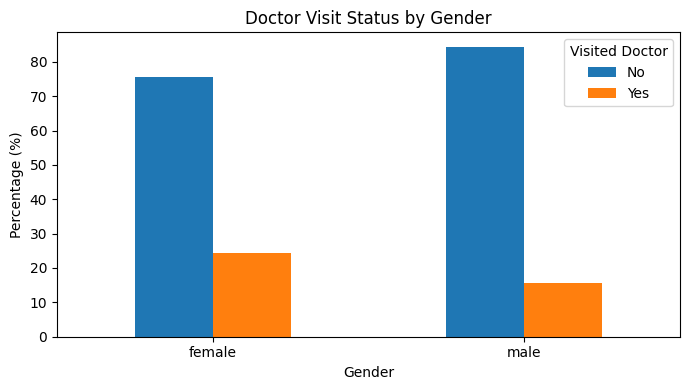

In [43]:
# Doctor Visit Status by Gender (%)
gender_visit_pct = pd.crosstab(doc_visit_data['gender'], doc_visit_data['visited_doctor'], 
                               normalize='index') * 100

gender_visit_pct.plot(kind='bar', figsize=(7, 4))

plt.title('Doctor Visit Status by Gender')
plt.xlabel('Gender')
plt.ylabel('Percentage (%)')
plt.xticks(rotation=0)
plt.legend(title='Visited Doctor')
plt.tight_layout()
plt.show()

In [44]:
# Actual Doctor Visit Counts by Gender
visit_gender = pd.crosstab(
    doc_visit_data['visits'],
    doc_visit_data['gender']
)

visit_gender

gender,female,male
visits,,
0,2042,2099
1,494,288
2,114,60
3,13,17
4,13,11
5,5,4
6,9,3
7,10,2
8,2,3


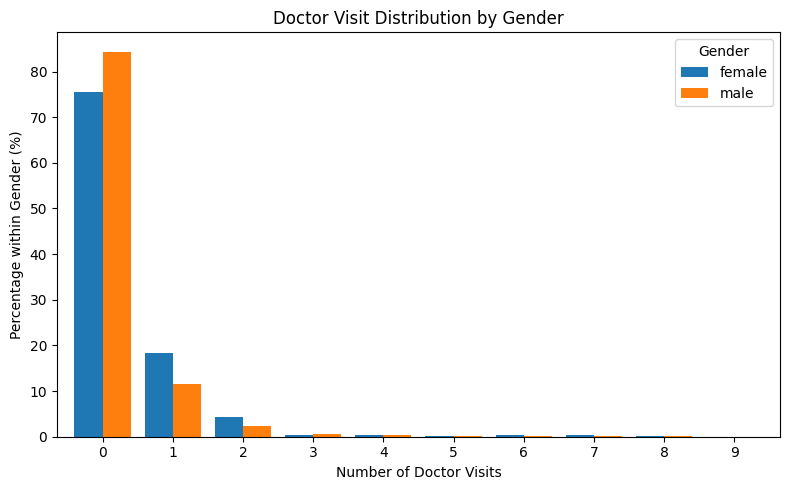

In [45]:
# Gender-wise Doctor Visit Percentage Distribution

visit_gender_pct = pd.crosstab(doc_visit_data['visits'], 
                               doc_visit_data['gender'],
                               normalize='columns'
                              ) * 100

visit_gender_pct.plot(kind='bar', figsize=(8, 5), width=0.8)

plt.title('Doctor Visit Distribution by Gender')
plt.xlabel('Number of Doctor Visits')
plt.ylabel('Percentage within Gender (%)')
plt.legend(title='Gender')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Doctor Visits by Gender - Key Insights

- **Females are more likely to have visited a doctor**: approximately **24.4%** of females visited a doctor, compared with **15.6%** of males, indicating a noticeable gender difference in doctor-visit rates.

- **A higher proportion of males had no doctor visits**: approximately **84.4%** of males reported zero visits, compared with **75.6%** of females.

- **Females recorded more frequent visits at lower counts**: **18.3%** of females had **one visit**, compared with **11.6%** of males. Similarly, **4.2%** of females had two visits, compared with **2.4%** of males.

- **Higher visit counts are rare for both genders**: the number of individuals declines substantially beyond two visits, with very few observations at three or more visits.

- Overall, **females show a higher prevalence of doctor visits than males** in this dataset. This suggests a potential association between gender and healthcare utilisation, although further analysis is needed to determine whether other factors, such as age, income, or health conditions, contribute to this difference.

### 9.2 Doctor Visits vs Age:

In [46]:
# Doctor Visit Status by Age
age_visit = pd.crosstab(doc_visit_data['age_years'], doc_visit_data['visited_doctor'])

age_visit

visited_doctor,No,Yes
age_years,,
19.0,638,114
22.0,1039,174
27.0,436,87
32.0,251,50
37.0,120,26
42.0,104,22
47.0,151,30
52.0,168,54
57.0,201,72


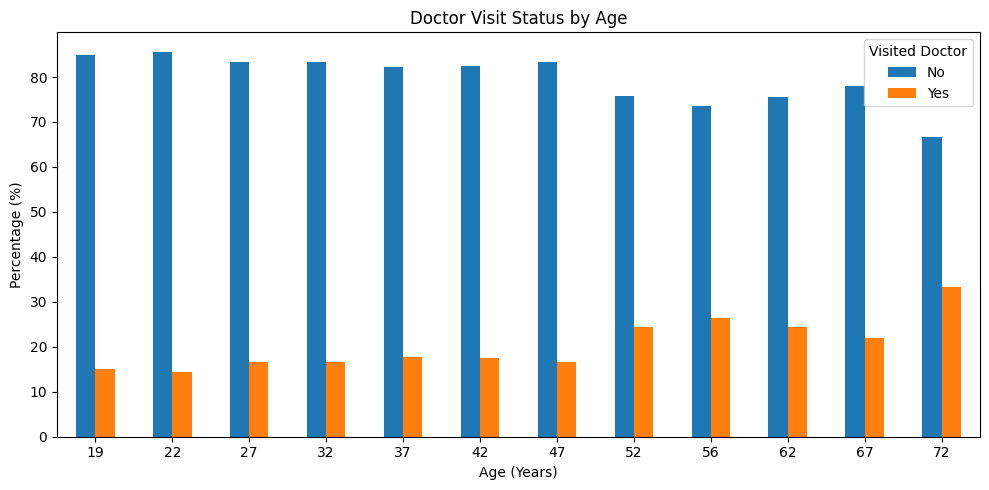

In [47]:
# Age-wise Doctor Visit Status (%)
age_visit_pct = pd.crosstab(doc_visit_data['age_years'],
                            doc_visit_data['visited_doctor'],
                            normalize='index'
                           ) * 100

ax = age_visit_pct.plot(kind='bar', figsize=(10, 5))

plt.title('Doctor Visit Status by Age')
plt.xlabel('Age (Years)')
plt.ylabel('Percentage (%)')
ax.set_xticklabels(age_visit_pct.index.astype(int), rotation=0)
plt.legend(title='Visited Doctor')
plt.tight_layout()
plt.show()

In [48]:
# Age-wise Doctor Visit Summary
age_summary = doc_visit_data.groupby('age_years').agg(
    Individuals=('visits', 'count'),
    Total_Visits=('visits', 'sum'),
    Average_Visits=('visits', 'mean')
).round(2)

age_summary.index = age_summary.index.astype(int)
age_summary

,Individuals,Total_Visits,Average_Visits
age_years,,,
19,752,160,0.21
22,1213,244,0.20
27,523,135,0.26
32,301,73,0.24
37,146,36,0.25
42,126,40,0.32
47,181,49,0.27
52,222,92,0.41
56,273,109,0.40


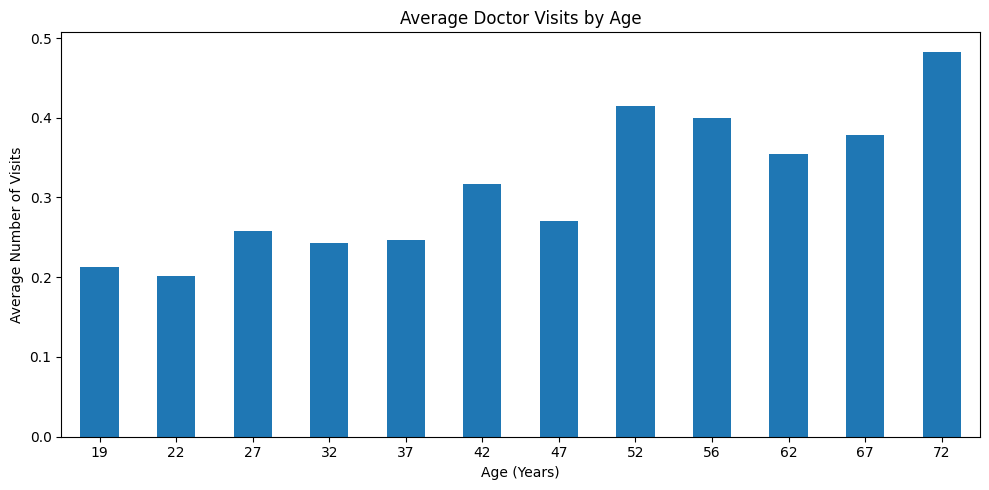

In [49]:
# Average Doctor Visits by Age
age_mean_visits = doc_visit_data.groupby('age_years')['visits'].mean()

ax = age_mean_visits.plot(kind='bar', figsize=(10, 5))

plt.title('Average Doctor Visits by Age')
plt.xlabel('Age (Years)')
plt.ylabel('Average Number of Visits')

ax.set_xticklabels(age_mean_visits.index.astype(int), rotation=0)

plt.tight_layout()
plt.show()

### Doctor Visits by Age - Key Insights

- **Doctor visit rates generally increase with age**, although the trend is not strictly linear. Older age groups tend to have higher doctor visit rates than younger groups.

- **The 72-year-old group has the highest visit rate (33.3%)** and the highest average number of visits (**0.48 per individual**), indicating greater healthcare utilization in this age group.

- **Younger individuals aged 19–32 show relatively lower doctor visit rates**, generally around 15–17%, with average visits ranging from 0.20 to 0.26 per individual.

- **Doctor visit rates become more noticeable from age 52 onward**, reaching approximately 24–26% among individuals aged 52–62, compared with lower rates in most younger groups.

- **Average visits generally rise with age, despite some fluctuations.** For example, the average decreases from 0.40 at age 57 to 0.35 at age 62, before increasing again at age 72.

- **The 72-year-old group records the highest total number of visits (397)**. Its larger sample size (822 individuals), together with its higher visit rate, contributes to this total.

- Overall, the analysis suggests a **positive association between age and doctor visits**, with older individuals generally showing greater healthcare utilization. However, this descriptive relationship does not establish that age alone explains the differences.

### 9.3 Doctor Visits vs Illness:

In [50]:
# Illness-wise Doctor Visit Summary
illness_summary = doc_visit_data.groupby('illness').agg(
    Individuals=('visits', 'count'),
    Total_Visits=('visits', 'sum'),
    Average_Visits=('visits', 'mean')
).round(2)

illness_summary

,Individuals,Total_Visits,Average_Visits
illness,,,
0,1554,122,0.08
1,1638,484,0.30
2,946,382,0.40
3,542,228,0.42
4,274,158,0.58
5,236,192,0.81


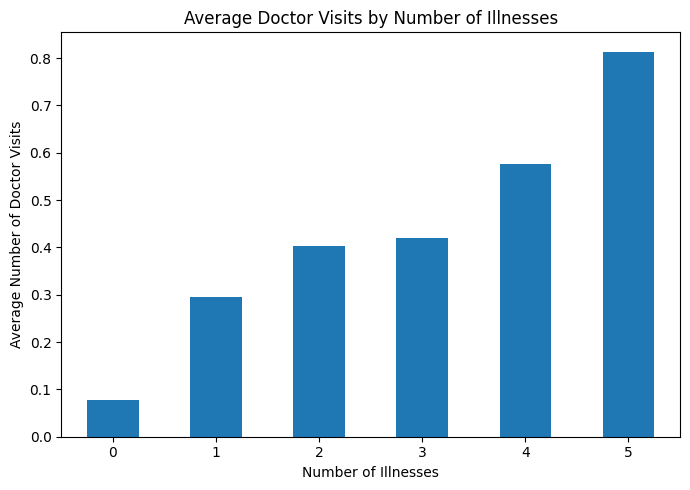

In [51]:
# Average Doctor Visits by Illness
illness_mean_visits = doc_visit_data.groupby('illness')['visits'].mean()

ax = illness_mean_visits.plot(kind='bar', figsize=(7, 5))

plt.title('Average Doctor Visits by Number of Illnesses')
plt.xlabel('Number of Illnesses')
plt.ylabel('Average Number of Doctor Visits')
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [52]:
# Doctor Visit Status by Number of Illnesses
illness_visit = pd.crosstab(doc_visit_data['illness'],
                            doc_visit_data['visited_doctor']
                           )

illness_visit

visited_doctor,No,Yes
illness,,
0,1449,105
1,1317,321
2,688,258
3,376,166
4,174,100
5,137,99


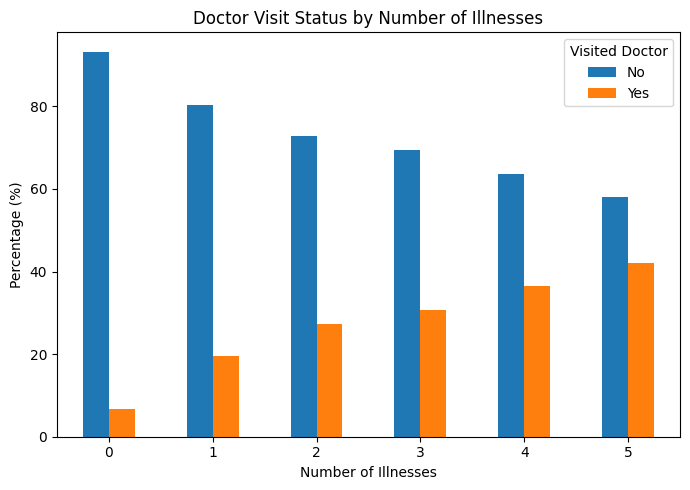

In [53]:
# Doctor Visit Status by Number of Illnesses (%)
illness_visit_pct = pd.crosstab(
    doc_visit_data['illness'],
    doc_visit_data['visited_doctor'],
    normalize='index'
) * 100

illness_visit_pct.plot(kind='bar', figsize=(7, 5))

plt.title('Doctor Visit Status by Number of Illnesses')
plt.xlabel('Number of Illnesses')
plt.ylabel('Percentage (%)')
plt.xticks(rotation=0)
plt.legend(title='Visited Doctor')
plt.tight_layout()
plt.show()

### Doctor Visits by Number of Illnesses - Key Insights

- **Doctor visit rates increase consistently with the number of illnesses.** The proportion of individuals who visited a doctor rises from **6.8% among those with no illnesses** to **42.0% among those with five illnesses**, indicating a clear association between illness count and healthcare utilization.

- **Individuals with no reported illnesses have the lowest average number of doctor visits (0.08)**, compared with **0.30 for those with one illness** and **0.40 for those with two illnesses**. This shows a substantial increase in average visits even with the presence of one or two illnesses.

- **Average doctor visits generally increase as illness count rises**, reaching **0.81 visits per individual among those with five illnesses**. This suggests that individuals reporting more illnesses tend to use healthcare services more frequently.

- **The largest group has one illness (1,638 individuals)**, followed by those with no illnesses (1,554). The number of individuals generally decreases at higher illness counts, with only **236 individuals reporting five illnesses**.

- **The relationship is particularly noticeable at higher illness counts:** approximately **36.5% of individuals with four illnesses** and **42.0% with five illnesses** visited a doctor, compared with **19.6% among those with one illness**.

- Overall, the analysis indicates a **positive association between the number of illnesses and doctor visits**: individuals reporting more illnesses generally have higher visit rates and average visit counts. However, this descriptive relationship does not establish causation.

### 9.4 Doctor Visits vs Reduced Activity:

In [54]:
# Reduced Activity-wise Doctor Visit Summary
reduced_summary = doc_visit_data.groupby('reduced').agg(
    Individuals=('visits', 'count'),
    Total_Visits=('visits', 'sum'),
    Average_Visits=('visits', 'mean')
).round(2)

reduced_summary

,Individuals,Total_Visits,Average_Visits
reduced,,,
0,4454,819,0.18
1,177,63,0.36
2,108,62,0.57
3,74,81,1.09
4,45,36,0.80
5,40,51,1.27
6,17,20,1.18
7,38,45,1.18
8,17,20,1.18


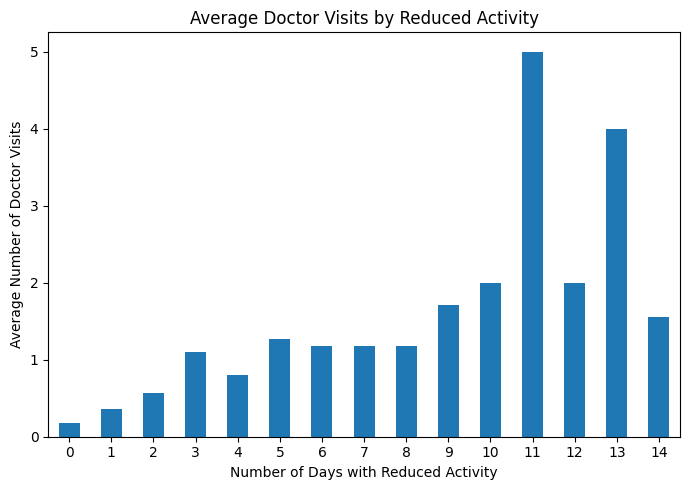

In [55]:
# Average Doctor Visits by Reduced Activity
reduced_mean_visits = doc_visit_data.groupby('reduced')['visits'].mean()

reduced_mean_visits.plot(kind='bar', figsize=(7, 5))

plt.title('Average Doctor Visits by Reduced Activity')
plt.xlabel('Number of Days with Reduced Activity')
plt.ylabel('Average Number of Doctor Visits')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [56]:
# Doctor Visit Status by Reduced Activity
reduced_visit = pd.crosstab(doc_visit_data['reduced'], doc_visit_data['visited_doctor'])
reduced_visit

visited_doctor,No,Yes
reduced,,
0,3778,676
1,129,48
2,63,45
3,30,44
4,20,25
5,15,25
6,5,12
7,15,23
8,7,10


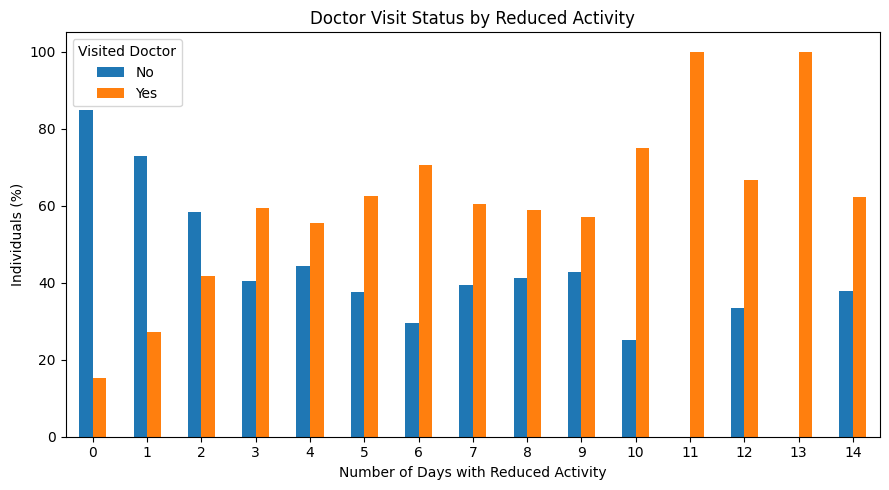

In [57]:
# Doctor Visit Status by Reduced Activity (%)
reduced_visit_pct = pd.crosstab(
    doc_visit_data['reduced'],
    doc_visit_data['visited_doctor'],
    normalize='index'
) * 100

reduced_visit_pct.plot(kind='bar', figsize=(9, 5))

plt.title('Doctor Visit Status by Reduced Activity')
plt.xlabel('Number of Days with Reduced Activity')
plt.ylabel('Individuals (%)')
plt.xticks(rotation=0)
plt.legend(title='Visited Doctor')
plt.tight_layout()
plt.show()

### Doctor Visits by Reduced Activity Days - Key Insights

- **Doctor visit rates generally increase with the number of reduced-activity days.** Among individuals reporting 0 reduced-activity days, only **15.2% visited a doctor**, compared with **62.2% among those reporting 14 days**, suggesting an association between reduced activity and healthcare utilization.

- **Individuals with no reduced-activity days have the lowest average number of doctor visits (0.18)**, while those reporting 10 or more days generally show higher average visits. The average reaches **5 visits for 11 days** and **4 visits for 13 days**, but these estimates are based on very small groups.

- **Most individuals reported no reduced-activity days:** **4,454 individuals**, representing approximately **85.8% of the dataset**. This makes zero the dominant category and means that estimates for many higher day counts are based on relatively few observations.

- **The 14-day category forms a noticeable secondary concentration**, with **188 individuals** and **291 total visits**, giving an average of **1.55 visits per individual**. This group also has a doctor-visit rate of approximately **62.2%**, suggesting that individuals reporting reduced activity throughout the full 14-day period tend to have greater healthcare utilisation.

- **Doctor visit rates exceed 50% for several higher reduced-activity categories**, including 3, 5, 6, 8, 10, 11, and 13 days. However, the pattern is not perfectly consistent, and some categories contain very few individuals.

- Overall, the analysis suggests a **positive association between reduced-activity days and doctor visits**. Individuals reporting more days of reduced activity generally show higher healthcare utilisation, although small sample sizes at higher day counts make some averages unstable and should be considered when interpreting the pattern.

### 9.5 Doctor Visits vs Health Score:

In [58]:
# Health Score-wise Doctor Visit Summary
health_summary = doc_visit_data.groupby('health').agg(
    Individuals=('visits', 'count'),
    Total_Visits=('visits', 'sum'),
    Average_Visits=('visits', 'mean')
).round(2)

health_summary

,Individuals,Total_Visits,Average_Visits
health,,,
0,3026,603,0.20
1,823,276,0.34
2,446,170,0.38
3,273,114,0.42
4,187,100,0.53
5,132,70,0.53
6,104,65,0.62
7,61,56,0.92
8,42,20,0.48


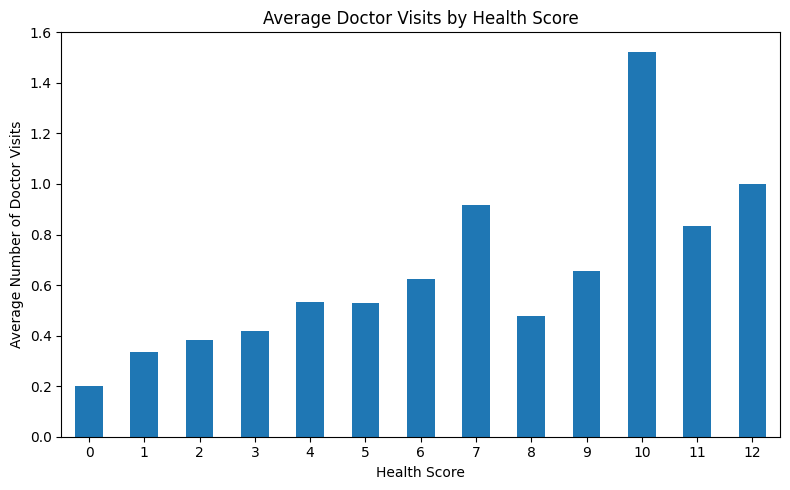

In [59]:
# Average Doctor Visits by Health Score
health_mean_visits = doc_visit_data.groupby('health')['visits'].mean()

health_mean_visits.plot(kind='bar', figsize=(8, 5))

plt.title('Average Doctor Visits by Health Score')
plt.xlabel('Health Score')
plt.ylabel('Average Number of Doctor Visits')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [60]:
# Doctor Visit Status by Health Score
health_visit = pd.crosstab(doc_visit_data['health'], doc_visit_data['visited_doctor'])
health_visit

visited_doctor,No,Yes
health,,
0,2571,455
1,630,193
2,337,109
3,203,70
4,135,52
5,95,37
6,63,41
7,31,30
8,29,13


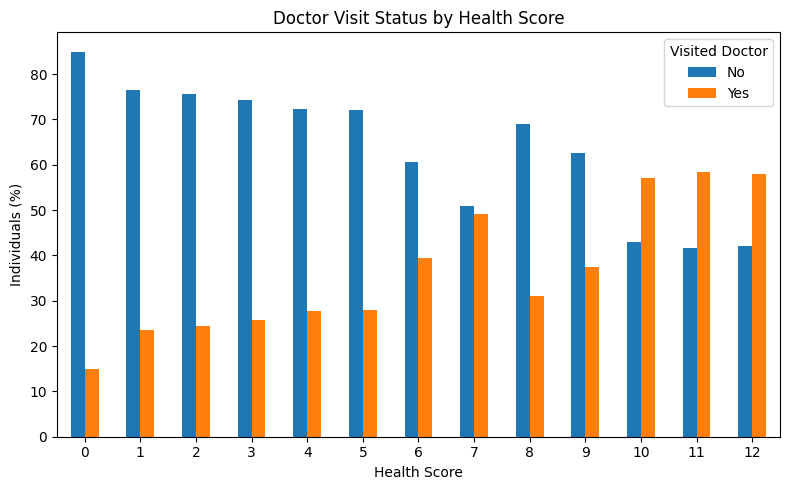

In [61]:
# Doctor Visit Status by Health Score (%)
health_visit_pct = pd.crosstab(
    doc_visit_data['health'],
    doc_visit_data['visited_doctor'],
    normalize='index'
) * 100

health_visit_pct.plot(kind='bar', figsize=(8, 5))

plt.title('Doctor Visit Status by Health Score')
plt.xlabel('Health Score')
plt.ylabel('Individuals (%)')
plt.xticks(rotation=0)
plt.legend(title='Visited Doctor')
plt.tight_layout()
plt.show()

### Doctor Visits by Health Score - Key Insights

- **Doctor visit rates generally increase with higher health scores.** The proportion of individuals who visited a doctor rises from **15.0% at score 0** to approximately **58% at scores 11–12**, suggesting an association between health score and healthcare utilization.

- **Individuals with a health score of 0 have the lowest average doctor visits (0.20)**, while the average reaches **1.52 visits at score 10**. This indicates generally higher healthcare utilization at higher scores, although the pattern is not consistent at every score.

- **The increase is not perfectly linear.** For example, the doctor visit rate drops from approximately **49% at score 7 to 31% at score 8**, before increasing again at higher scores.

- **Higher health scores have fewer observations.** The number of individuals declines from **3,026 at score 0 to just 19 at score 12**, so averages and percentages at higher scores are less stable and should be interpreted cautiously.

- **Overall, higher health scores are generally associated with more doctor visits**, but the fluctuations and small sample sizes at higher scores should be considered when interpreting this relationship.

### 9.6 Doctor Visits vs Chronic Conditions:

In [62]:
# Chronic Conditions-wise Doctor Visit Summary
chronic_summary = doc_visit_data.groupby(['nchronic', 'lchronic']).agg(
    Individuals=('visits', 'count'),
    Total_Visits=('visits', 'sum'),
    Average_Visits=('visits', 'mean')
).round(2)

chronic_summary

Individuals  Total_Visits  Average_Visits
nchronic lchronic                                           
no       no               2493           478            0.19
         yes               605           365            0.60
yes      no               2092           723            0.35

In [63]:
# Creating a Chronic Condition Category for easier interpretation
doc_visit_data['chronic_category'] = np.select(
    [
        (doc_visit_data['nchronic'] == 'no') & (doc_visit_data['lchronic'] == 'no'),
        (doc_visit_data['nchronic'] == 'no') & (doc_visit_data['lchronic'] == 'yes'),
        (doc_visit_data['nchronic'] == 'yes') & (doc_visit_data['lchronic'] == 'no')
    ],
    [
        'No Chronic Condition',
        'Activity-Limiting Chronic Condition',
        'Non-Limiting Chronic Condition'
    ],
    default='Other'
)

In [64]:
# Chronic Category-wise Doctor Visit Summary
chronic_summary = doc_visit_data.groupby('chronic_category').agg(
    Individuals=('visits', 'count'),
    Total_Visits=('visits', 'sum'),
    Average_Visits=('visits', 'mean')
).round(2)

chronic_summary

,Individuals,Total_Visits,Average_Visits
chronic_category,,,
Activity-Limiting Chronic Condition,605,365,0.60
No Chronic Condition,2493,478,0.19
Non-Limiting Chronic Condition,2092,723,0.35


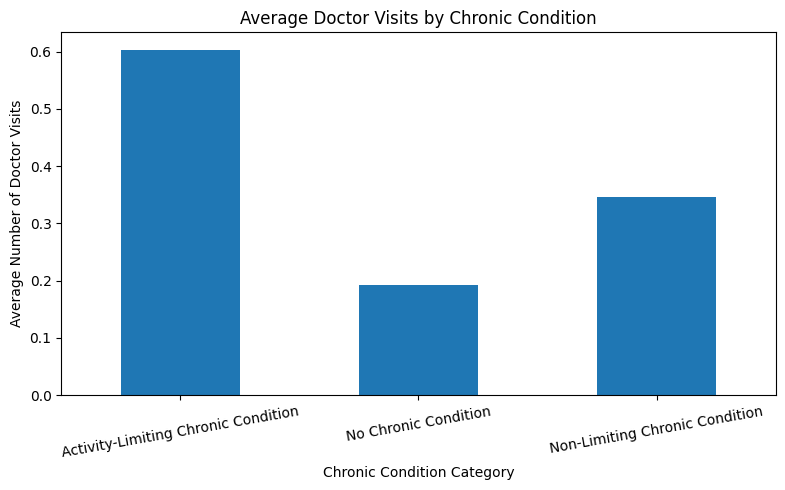

In [65]:
# Average Doctor Visits by Chronic Condition
chronic_mean_visits = doc_visit_data.groupby('chronic_category')['visits'].mean()

chronic_mean_visits.plot(kind='bar', figsize=(8, 5))

plt.title('Average Doctor Visits by Chronic Condition')
plt.xlabel('Chronic Condition Category')
plt.ylabel('Average Number of Doctor Visits')
plt.xticks(rotation=10)
plt.tight_layout()
plt.show()

In [66]:
# Doctor Visit Status by Chronic Condition
chronic_visit = pd.crosstab(doc_visit_data['chronic_category'], 
                                doc_visit_data['visited_doctor'])
chronic_visit

visited_doctor,No,Yes
chronic_category,,
Activity-Limiting Chronic Condition,393,212
No Chronic Condition,2151,342
Non-Limiting Chronic Condition,1597,495


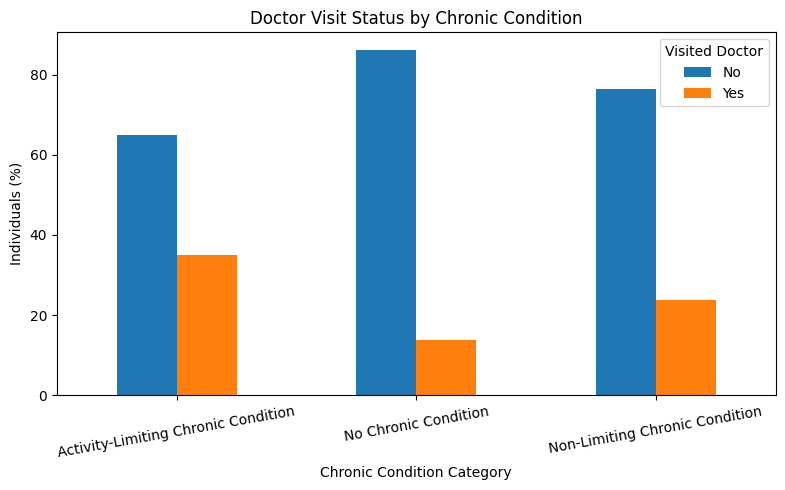

In [67]:
# Doctor Visit Status by Chronic Condition (%)
chronic_visit_pct = pd.crosstab(
    doc_visit_data['chronic_category'],
    doc_visit_data['visited_doctor'],
    normalize='index'
) * 100

chronic_visit_pct.plot(kind='bar', figsize=(8, 5))

plt.title('Doctor Visit Status by Chronic Condition')
plt.xlabel('Chronic Condition Category')
plt.ylabel('Individuals (%)')
plt.xticks(rotation=10)
plt.legend(title='Visited Doctor')
plt.tight_layout()
plt.show()

### Doctor Visits by Chronic Condition - Key Insights

- **Individuals with activity-limiting chronic conditions have the highest doctor visit rate (35.0%)**, compared with **23.7% for non-limiting chronic conditions** and **13.7% for individuals without chronic conditions**.

- **Average doctor visits are highest among individuals with activity-limiting chronic conditions (0.60)**, followed by those with non-limiting chronic conditions (0.35) and those without chronic conditions (0.19). This suggests greater healthcare utilization among individuals whose conditions limit daily activities.

- **Individuals without chronic conditions form the largest group (2,493)**, while **605 individuals** have activity-limiting chronic conditions. Despite their smaller number, the activity-limiting group has a substantially higher doctor visit rate.

- **Non-limiting chronic conditions are also associated with greater healthcare utilization** than having no chronic condition, with a higher visit rate and average number of visits.

- Overall, the analysis suggests that **doctor visits are more common among individuals with chronic conditions, particularly those that limit daily activities**. This indicates an association between chronic condition status and healthcare utilization, but does not establish causation.

### 9.7 Doctor Visits vs Healthcare Coverage:

In [68]:
# Healthcare Coverage-wise Doctor Visit Summary
coverage_summary = pd.concat({
    'Private Insurance': doc_visit_data.groupby('private')['visits'].agg(
        Individuals='count',
        Total_Visits='sum',
        Average_Visits='mean'
    ),
    'Free Insurance (Low Income)': doc_visit_data.groupby('freepoor')['visits'].agg(
        Individuals='count',
        Total_Visits='sum',
        Average_Visits='mean'
    ),
    'Free Insurance (Special Status)': doc_visit_data.groupby('freerepat')['visits'].agg(
        Individuals='count',
        Total_Visits='sum',
        Average_Visits='mean'
    )
}, names=['Coverage Type', 'Coverage Status']).round(2)

coverage_summary

Individuals  Total_Visits  \
Coverage Type                   Coverage Status                              
Private Insurance               no                      2892           889   
                                yes                     2298           677   
Free Insurance (Low Income)     no                      4968          1531   
                                yes                      222            35   
Free Insurance (Special Status) no                      4099          1057   
                                yes                     1091           509   

                                                 Average_Visits  
Coverage Type                   Coverage Status                  
Private Insurance               no                         0.31  
                                yes                        0.29  
Free Insurance (Low Income)     no                         0.31  
                                yes                        0.16  
Free Insurance (Special Status) no                         0.26  
                                yes                        0.47

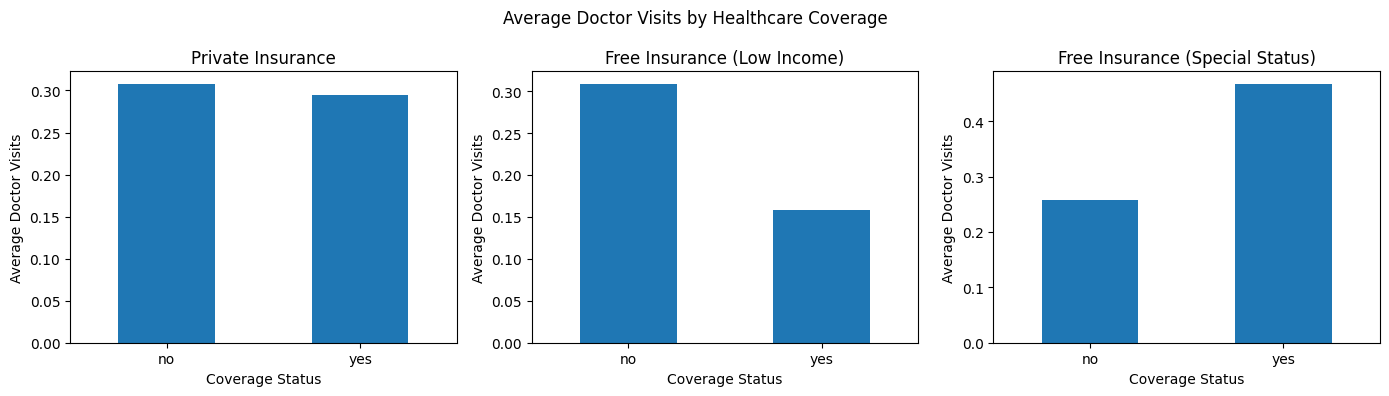

In [69]:
# Average Doctor Visits by Healthcare Coverage
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

# Private Insurance
doc_visit_data.groupby('private')['visits'].mean().plot(kind='bar', ax=axes[0])

axes[0].set_title('Private Insurance')
axes[0].set_xlabel('Coverage Status')
axes[0].set_ylabel('Average Doctor Visits')
axes[0].tick_params(axis='x', rotation=0)

# Free Insurance (Low Income)
doc_visit_data.groupby('freepoor')['visits'].mean().plot(kind='bar', ax=axes[1])

axes[1].set_title('Free Insurance (Low Income)')
axes[1].set_xlabel('Coverage Status')
axes[1].set_ylabel('Average Doctor Visits')
axes[1].tick_params(axis='x', rotation=0)

# Free Insurance (Special Status)
doc_visit_data.groupby('freerepat')['visits'].mean().plot(kind='bar', ax=axes[2])

axes[2].set_title('Free Insurance (Special Status)')
axes[2].set_xlabel('Coverage Status')
axes[2].set_ylabel('Average Doctor Visits')
axes[2].tick_params(axis='x', rotation=0)

fig.suptitle('Average Doctor Visits by Healthcare Coverage')
plt.tight_layout()
plt.show()

In [70]:
# Doctor Visit Status by Healthcare Coverage
coverage_crosstab = pd.concat({
    'Private Insurance': pd.crosstab(
        doc_visit_data['private'],
        doc_visit_data['visited_doctor']
    ),
    'Free Insurance (Low Income)': pd.crosstab(
        doc_visit_data['freepoor'],
        doc_visit_data['visited_doctor']
    ),
    'Free Insurance (Special Status)': pd.crosstab(
        doc_visit_data['freerepat'],
        doc_visit_data['visited_doctor']
    )
}, names=['Coverage Type', 'Coverage Status'])

coverage_crosstab

visited_doctor                                     No   Yes
Coverage Type                   Coverage Status            
Private Insurance               no               2303   589
                                yes              1838   460
Free Insurance (Low Income)     no               3939  1029
                                yes               202    20
Free Insurance (Special Status) no               3395   704
                                yes               746   345

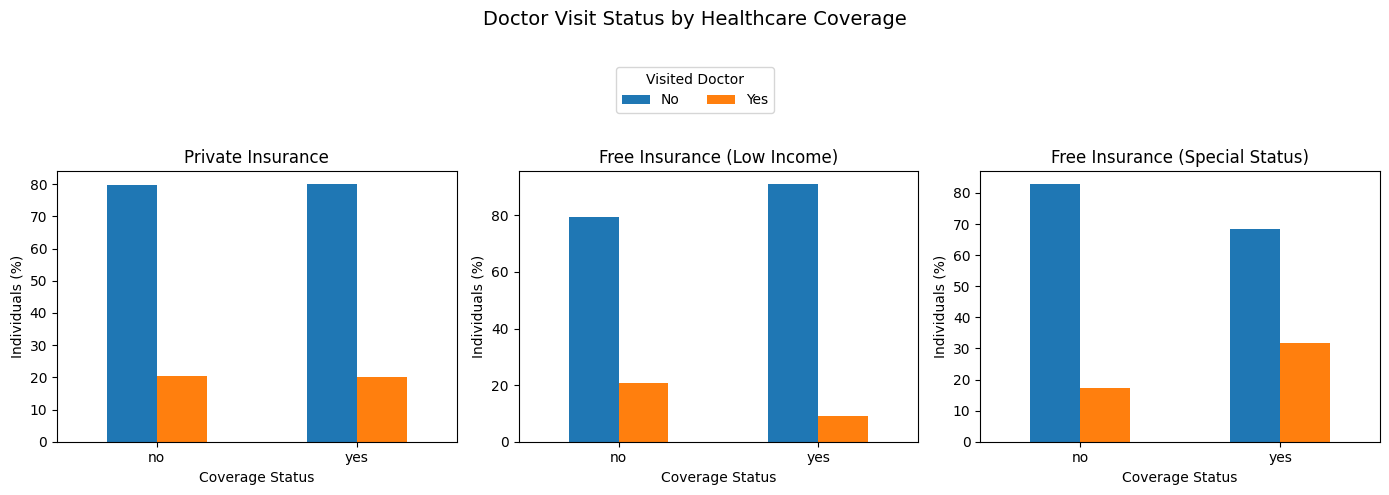

In [71]:
# Doctor Visit Status by Healthcare Coverage (%)
fig, axes = plt.subplots(1, 3, figsize=(14, 5))

# Private Insurance
private_pct = pd.crosstab(
    doc_visit_data['private'],
    doc_visit_data['visited_doctor'],
    normalize='index'
) * 100

private_pct.plot(kind='bar', ax=axes[0])
axes[0].set_title('Private Insurance')
axes[0].set_xlabel('Coverage Status')
axes[0].set_ylabel('Individuals (%)')
axes[0].tick_params(axis='x', rotation=0)

# Free Insurance (Low Income)
freepoor_pct = pd.crosstab(
    doc_visit_data['freepoor'],
    doc_visit_data['visited_doctor'],
    normalize='index'
) * 100

freepoor_pct.plot(kind='bar', ax=axes[1])
axes[1].set_title('Free Insurance (Low Income)')
axes[1].set_xlabel('Coverage Status')
axes[1].set_ylabel('Individuals (%)')
axes[1].tick_params(axis='x', rotation=0)

# Free Insurance (Special Status)
freerepat_pct = pd.crosstab(
    doc_visit_data['freerepat'],
    doc_visit_data['visited_doctor'],
    normalize='index'
) * 100

freerepat_pct.plot(kind='bar', ax=axes[2])
axes[2].set_title('Free Insurance (Special Status)')
axes[2].set_xlabel('Coverage Status')
axes[2].set_ylabel('Individuals (%)')
axes[2].tick_params(axis='x', rotation=0)

# Overall Title and Shared Legend
fig.suptitle('Doctor Visit Status by Healthcare Coverage', fontsize=14)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    title='Visited Doctor',
    loc='upper center',
    bbox_to_anchor=(0.5, 0.88),
    ncol=2
)

# Remove individual legends
for ax in axes:
    ax.get_legend().remove()

plt.tight_layout(rect=[0, 0, 1, 0.8])
plt.show()

### Doctor Visits by Healthcare Coverage - Key Insights

- **Private insurance shows little difference in doctor visit rates:** approximately **20.0% of privately insured individuals** visited a doctor, compared with **20.3% of those without private insurance**. Average visits are also similar (0.29 vs. 0.31), suggesting little apparent difference in healthcare utilization by private insurance status.

- **Individuals with free government insurance due to low income have a lower doctor visit rate:** only **9.0%** visited a doctor, compared with **20.7%** among those without this coverage. Their average visits are also lower (**0.16 vs. 0.31**).

- **Individuals with free government insurance due to special status (old age, disability, or veteran status) show higher healthcare utilization:** approximately **31.6%** visited a doctor, compared with **17.2%** among those without this coverage. Their average visits are also higher (**0.47 vs. 0.26**).

- **The strongest differences appear in government insurance categories rather than private insurance.** Low-income coverage is associated with lower observed visit rates, while special-status coverage is associated with higher rates. These patterns may reflect differences in health needs or other characteristics, rather than insurance coverage alone.

- Overall, **doctor visit patterns vary across healthcare coverage categories**. Private insurance status shows little difference, while government coverage groups show more noticeable differences. These are descriptive associations and do not establish that insurance status causes higher or lower healthcare utilization.

### 9.8 Income vs Doctor Visits:

In [72]:
# Income-wise Doctor Visit Summary
income_summary = doc_visit_data.groupby('income_dollars').agg(
    Individuals=('visits', 'count'),
    Total_Visits=('visits', 'sum'),
    Average_Visits=('visits', 'mean')
).round(2)

income_summary

,Individuals,Total_Visits,Average_Visits
income_dollars,,,
0.0,79,29,0.37
100.0,35,17,0.49
600.0,80,16,0.20
1500.0,249,87,0.35
2500.0,1195,503,0.42
3500.0,462,166,0.36
4500.0,400,122,0.30
5500.0,467,118,0.25
6500.0,455,112,0.25


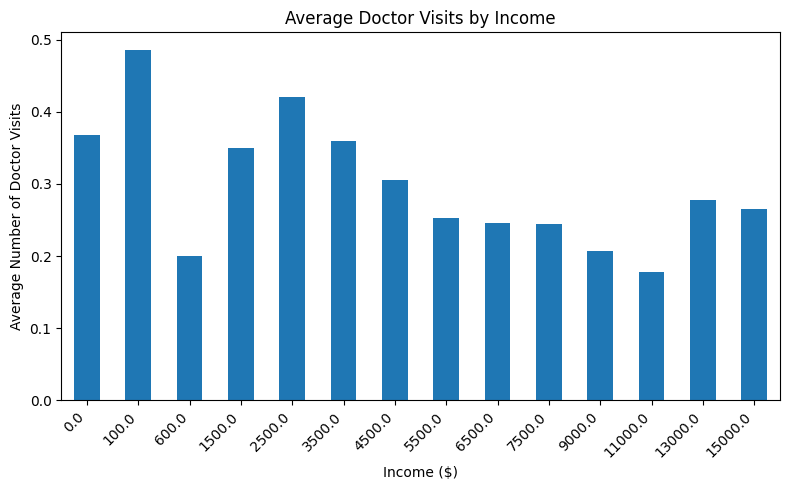

In [73]:
# Average Doctor Visits by Income
income_mean_visits = doc_visit_data.groupby('income_dollars')['visits'].mean()

income_mean_visits.plot(kind='bar', figsize=(8, 5))

plt.title('Average Doctor Visits by Income')
plt.xlabel('Income ($)')
plt.ylabel('Average Number of Doctor Visits')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [74]:
# Doctor Visit Status by Income
income_visit = pd.crosstab(doc_visit_data['income_dollars'], 
                               doc_visit_data['visited_doctor'])
income_visit

visited_doctor,No,Yes
income_dollars,,
0.0,66,13
100.0,30,5
600.0,68,12
1500.0,195,54
2500.0,859,336
3500.0,361,101
4500.0,314,86
5500.0,387,80
6500.0,370,85


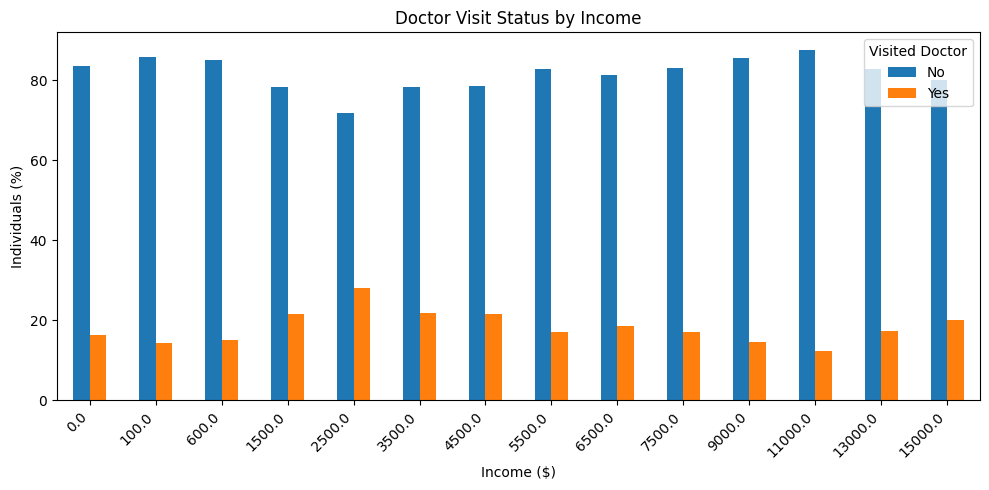

In [75]:
# Doctor Visit Status by Income (%)
income_visit_pct = pd.crosstab(
    doc_visit_data['income_dollars'],
    doc_visit_data['visited_doctor'],
    normalize='index'
) * 100

income_visit_pct.plot(kind='bar', figsize=(10, 5))

plt.title('Doctor Visit Status by Income')
plt.xlabel('Income ($)')
plt.ylabel('Individuals (%)')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Visited Doctor')
plt.tight_layout()
plt.show()

### Income vs. Doctor Visits — Key Insights

- **The $2,500 income group has the highest number of individuals:** 1,195 individuals belong to this group, making it the largest income category in the dataset. It also records the highest total doctor visits (503), contributing substantially to overall healthcare utilisation.

- **Average doctor visits generally decrease as income increases:** average visits decline from **0.42 at 2,500 dollars** to **0.18 at 11,000 dollars**. However, the pattern is not perfectly consistent, as some income groups show small increases.

- **The $2,500 income group has the highest doctor visit rate:** approximately **28.1%** of individuals in this group visited a doctor, compared with around **12.5% at 11,000 dollars**. This suggests that healthcare utilisation varies across income levels, with no consistent increase at higher incomes.

- **The lowest-income groups show varying visit patterns:** individuals earning 100 dollars have an average of 0.49 visits, while those earning 600 dollars average only 0.20. However, these groups contain just 35 and 80 individuals, respectively, so their averages may be less stable.

- **Higher-income groups generally have lower doctor visit rates:** for example, approximately **14.6% at 9,000 dollars** and **12.5% at 11,000 dollars** visited a doctor. The rate then rises to **17.3% at 13,000 dollars** and **20.0% at 15,000 dollars**, showing that the relationship is not strictly linear.

- **Overall, income alone does not fully explain doctor visit patterns.** Although several higher-income groups show lower average visits and visit rates, differences in health conditions, insurance coverage, age, and other factors may also influence healthcare utilisation. These findings show associations, not causation.

## 10. Correlation Analysis:

In [76]:
corr_cols = [
    'visits',
    'age_years',
    'income_dollars',
    'illness',
    'reduced',
    'health'
]

correlation = doc_visit_data[corr_cols].corr()

correlation

,visits,age_years,income_dollars,illness,reduced,health
visits,1.000000,0.124537,-0.076840,0.223552,0.418954,0.193272
age_years,0.124537,1.000000,-0.271073,0.204984,0.094745,0.018616
income_dollars,-0.076840,-0.271073,1.000000,-0.148812,-0.047545,-0.085790
illness,0.223552,0.204984,-0.148812,1.000000,0.218116,0.360110
reduced,0.418954,0.094745,-0.047545,0.218116,1.000000,0.280208
health,0.193272,0.018616,-0.085790,0.360110,0.280208,1.000000


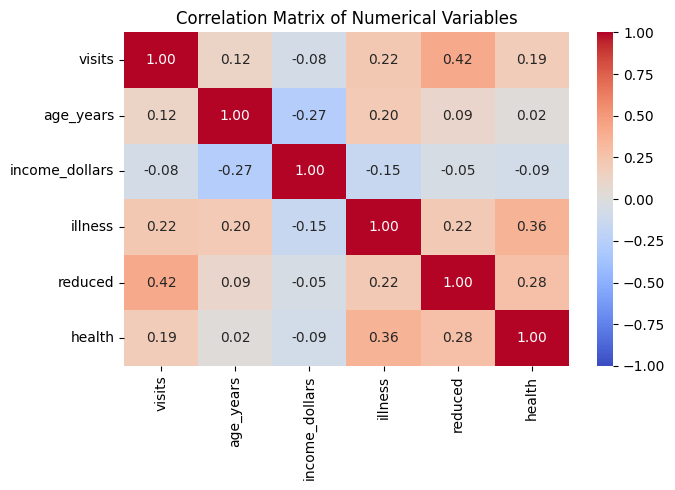

In [80]:
# Correlation Heatmap
plt.figure(figsize=(7, 5))

sns.heatmap(correlation, annot=True, cmap='coolwarm', 
            fmt='.2f', vmin=-1, vmax=1)

plt.title('Correlation Matrix of Numerical Variables')
plt.tight_layout()
plt.show()

### Correlation Analysis — Key Insights

- **Reduced activity has the strongest positive correlation with doctor visits (0.42):** Individuals reporting more days of reduced activity tend to have more doctor visits, suggesting that activity limitations are an important indicator of healthcare utilization.

- **Number of illnesses shows a positive correlation with doctor visits (0.22):** Individuals with more illnesses generally tend to have more doctor visits, although the relationship is relatively weak.

- **Health score has a positive correlation with doctor visits (0.19):** Doctor visits tend to increase slightly with higher health scores. However, the exact interpretation depends on how the health score is defined and coded.

- **Age has a weak positive correlation with doctor visits (0.12):** Older individuals tend to have slightly more doctor visits, but age alone has a limited linear relationship with visit frequency.

- **Income has a very weak negative correlation with doctor visits (-0.08):** Doctor visits tend to decrease slightly as income increases, but the relationship is too weak to suggest a meaningful linear association on its own.

- **Illnesses and health score show a moderate positive correlation (0.36):** Individuals with more illnesses tend to have higher health scores, indicating that these variables may capture related aspects of health status, depending on the score's coding.

- **Age and income have a negative correlation (-0.27):** Older individuals tend to have lower income in this dataset, suggesting a moderate inverse relationship between these variables.

- **Most other numerical variable pairs have weak correlations:** This indicates that their relationships are generally limited in terms of linear association, although non-linear relationships may still exist.

- **Overall, reduced activity, illness count, and health score show stronger relationships with doctor visits than age and income.** These variables may be useful predictors in subsequent modelling, but correlation does not establish causation, and their actual predictive value should be evaluated during model development.

## 11. Multivariate Analysis

### 11.1 Age and Gender vs. Doctor Visits:

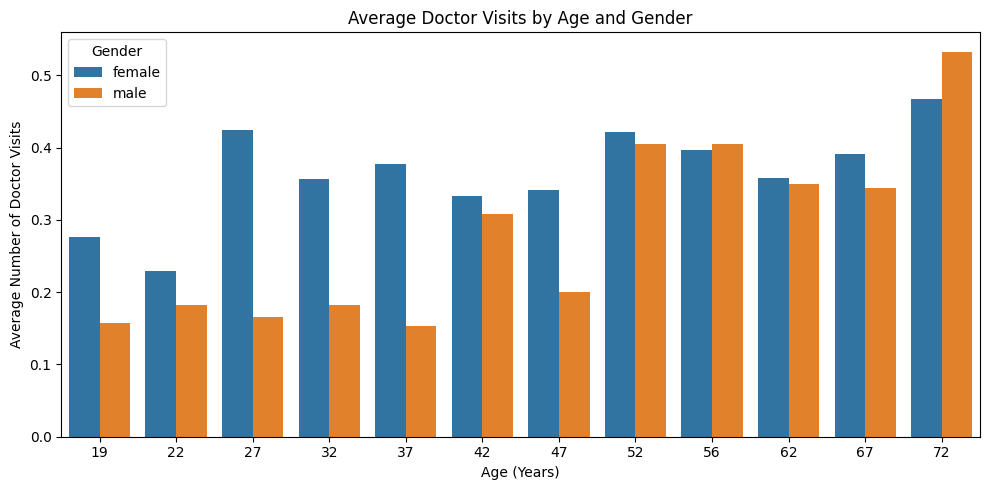

In [85]:
# Average Doctor Visits by Age and Gender
plt.figure(figsize=(10, 5))

sns.barplot(data=doc_visit_data, x=doc_visit_data['age_years'].astype(int),
            y='visits', hue='gender', errorbar=None)

plt.title('Average Doctor Visits by Age and Gender')
plt.xlabel('Age (Years)')
plt.ylabel('Average Number of Doctor Visits')
plt.legend(title='Gender')
plt.tight_layout()
plt.show()

### Average Doctor Visits by Age and Gender — Key Insights

- **Females generally have higher average doctor visits than males at younger ages:** From ages 19 to 47, females consistently show higher average visits, with the largest differences around ages 27 and 37.

- **The gender gap narrows at older ages:** At ages 52 and 56, average doctor visits are nearly equal for both genders, with males slightly higher at age 56.

- **Doctor visits generally increase with age for both genders:** Average visits tend to be higher among older individuals, although the pattern fluctuates across age groups rather than increasing steadily.

- **Age 72 has the highest average doctor visits for both genders:** Females average approximately **0.47 visits**, while males average around **0.53 visits**, making this the highest-visit age group in the chart.

- **Males show a noticeable increase in average visits after age 47:** Their average rises from approximately 0.20 at age 47 to around 0.41 at age 52, remaining relatively high in subsequent age groups.

- **Gender differences vary across age groups:** Females have higher averages in most younger and several older groups, while males record slightly higher averages at ages 56 and 72. This suggests that the relationship between age and healthcare utilization may differ by gender.

- **Overall, age and gender together reveal differences in healthcare utilization that are not apparent when examining either variable separately.** However, these are descriptive patterns, and the differences should be interpreted cautiously because the number of individuals may vary across age and gender groups.

### 11.2 Age and Illness vs. Doctor Visits:

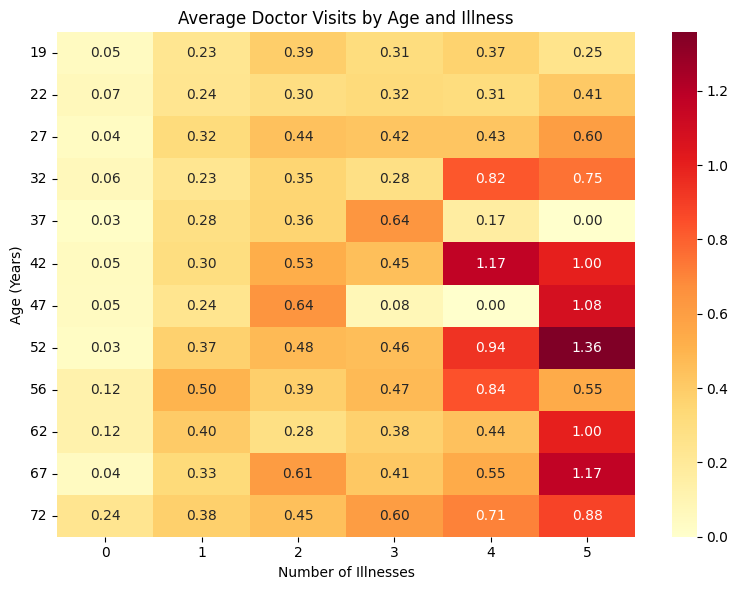

In [88]:
# Average Doctor Visits by Age and Illness
age_illness_visits = doc_visit_data.pivot_table(
    index=doc_visit_data['age_years'].astype(int),
    columns='illness',
    values='visits',
    aggfunc='mean'
)

plt.figure(figsize=(8, 6))

sns.heatmap(age_illness_visits, annot=True, cmap='YlOrRd', fmt='.2f')

plt.title('Average Doctor Visits by Age and Illness')
plt.xlabel('Number of Illnesses')
plt.ylabel('Age (Years)')
plt.yticks(rotation = 0)
plt.tight_layout()
plt.show()

### Average Doctor Visits by Age and Number of Illnesses — Key Insights

- **Doctor visits generally increase with the number of illnesses:** Across most age groups, individuals with more illnesses tend to have higher average doctor visits, suggesting that a greater illness burden is associated with increased healthcare utilization.

- **Individuals with no illnesses have consistently low average visits:** Across most age groups, the average remains below 0.12 visits, except at age 72, where it reaches 0.24. This indicates that doctor visits are generally less frequent among individuals reporting no illnesses.

- **Older individuals with multiple illnesses show higher average visits:** At age 52, individuals with five illnesses record the highest average in the chart at **1.36 visits**, followed by age 67 with five illnesses at 1.17 visits and age 42 with four illnesses at 1.17 visits.

- **The relationship is not perfectly consistent across all age groups:** For example, at age 37, the average falls to 0.17 for four illnesses and 0.00 for five illnesses. Such variations may reflect small group sizes rather than a genuine reduction in healthcare needs.

- **Age 72 shows relatively high doctor visits across several illness categories:** Average visits range from 0.24 for no illnesses to 0.88 for five illnesses, indicating higher healthcare utilization among older individuals, particularly those reporting multiple illnesses.

- **The effect of illness count varies across age groups:** For example, at age 27, average visits rise to 0.60 for five illnesses, while at age 32, they reach 0.82 for four illnesses. This suggests that the relationship between illness burden and healthcare utilization may differ by age.

- **Overall, the heatmap suggests that a higher number of illnesses is generally associated with more doctor visits, particularly among older individuals.** However, some irregular values may result from small group sizes, so the number of individuals in each age–illness combination should be checked before drawing firm conclusions.

### 11.3 Illness and Private Insurance vs. Doctor Visits:

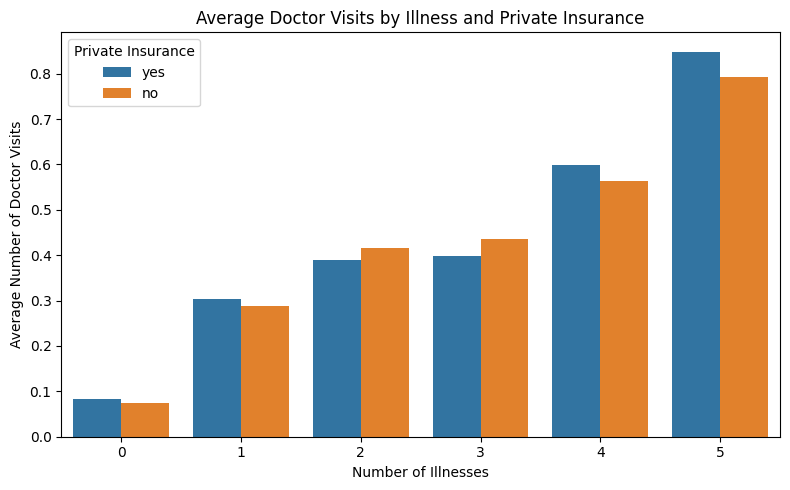

In [90]:
# Average Doctor Visits by Illness and Private Insurance
plt.figure(figsize=(8, 5))

sns.barplot(data=doc_visit_data, x='illness', y='visits',
            hue='private', errorbar=None)

plt.title('Average Doctor Visits by Illness and Private Insurance')
plt.xlabel('Number of Illnesses')
plt.ylabel('Average Number of Doctor Visits')
plt.legend(title='Private Insurance')
plt.tight_layout()
plt.show()

### Average Doctor Visits by Illness and Private Insurance — Key Insights

- **Average doctor visits increase with the number of illnesses for both insurance groups:** Individuals with five illnesses have the highest average visits, at approximately **0.85 for those with private insurance** and **0.79 for those without it**.

- **Individuals with no illnesses have very low average visits:** The averages are approximately 0.08 for those with private insurance and 0.07 for those without it, showing that doctor visits are generally less frequent among individuals reporting no illnesses.

- **Private insurance holders have slightly higher average visits for 0, 1, 4, and 5 illnesses:** This suggests that insured individuals in these illness categories tend to use healthcare services slightly more frequently.

- **Individuals without private insurance have higher average visits for 2 and 3 illnesses:** The differences are small, indicating that private insurance coverage does not consistently correspond to higher doctor visit frequency across all illness levels.

- **The difference between insurance groups is relatively small:** Both groups show a similar upward pattern as the number of illnesses increases, suggesting that **illness burden is more consistently associated with doctor visits than private insurance status** in this comparison.

- **Overall, individuals with more illnesses tend to have more doctor visits regardless of private insurance coverage.** However, these are descriptive associations; other factors, such as age, income, and health conditions, may also influence healthcare utilization.

## 12. Overall Key Findings:

- **Doctor visits are highly concentrated at zero:** Out of 5,190 individuals, **79.79% had no doctor visits**, while only 20.21% visited a doctor at least once. The target variable is therefore highly right-skewed and zero-heavy, which is important for model selection.

- **Age is associated with healthcare utilization:** Older individuals, particularly those aged 72, generally show higher average doctor visits than younger individuals. However, the relationship is not perfectly consistent across all age groups.

- **Gender differences are evident:** Females generally have higher average doctor visits than males, especially at younger ages. At age 72, males show a higher average, indicating that gender differences vary with age.

- **Illness burden is an important indicator of doctor visits:** Average visits generally increase as the number of illnesses rises, from 0.08 among individuals reporting no illnesses to 0.81 among those reporting five illnesses.

- **Reduced activity has the strongest correlation with doctor visits:** The correlation is **0.42**, suggesting that individuals experiencing more days of reduced activity tend to have more doctor visits. Illness count and health score also show positive correlations with visits, at 0.22 and 0.19, respectively.

- **Chronic conditions are associated with greater healthcare utilization:** Individuals with activity-limiting chronic conditions average **0.60 doctor visits**, compared with 0.35 for those with non-limiting chronic conditions and 0.19 for those without chronic conditions.

- **Healthcare coverage shows mixed patterns:** Private insurance holders and non-holders have similar average visit levels. Individuals with free insurance due to special status average more visits (0.47) than those without it (0.26), while the low-income free-insurance group shows fewer visits (0.16 versus 0.31). These differences do not establish that insurance itself causes higher or lower utilization.

- **Income has a weak relationship with doctor visits:** The correlation is **-0.08**, indicating little linear association. Although several higher-income groups show lower visit rates, the overall pattern is not consistent.

- **Health and demographic variables show different levels of association:** Age has a weak positive correlation with visits (0.12), while income has a weak negative correlation (-0.08). Illness count, reduced activity, and health score appear more informative for understanding healthcare utilization.

- **The dataset contains important class imbalance and potentially small subgroups:** Most individuals report zero visits, while very few report many visits. Some age–illness combinations also have unusually high or low averages, which may reflect small sample sizes and should be checked before drawing conclusions.

- **Overall finding:** Healthcare utilization in this dataset is most clearly associated with **reduced activity, illness burden, chronic conditions, and age-related patterns**. These findings can guide feature selection and subsequent modelling, but relationships should be validated through statistical testing and model evaluation rather than interpreted as causal effects.

## 13. Recommendations:

- **Prioritize individuals with greater healthcare needs:** Focus on individuals with multiple illnesses, chronic conditions, and frequent activity limitations, as these groups tend to have higher average doctor visits.

- **Improve healthcare access for potentially underserved groups:** Investigate why individuals receiving free insurance due to low income have fewer average visits. Financial, geographical, or other barriers may limit their access to healthcare.

- **Consider age and gender differences in healthcare planning:** Develop age-appropriate healthcare strategies, particularly for older individuals, while considering differences in visit patterns between males and females.

- **Strengthen preventive healthcare:** Encourage regular health check-ups and early intervention, especially for individuals with chronic conditions or multiple illnesses, to help manage health problems before they worsen.

- **Investigate the reasons behind low doctor visit rates:** Since nearly 80% of individuals reported no doctor visits, examine whether this reflects low healthcare needs, access barriers, or unmet medical needs rather than assuming that everyone requires medical attention.

- **Use health-related variables carefully in predictive modelling:** Prioritize illness count, reduced activity, chronic conditions, and other relevant health indicators as potential predictors, and evaluate their contribution using appropriate model-validation techniques.

- **Address the imbalance in the target variable:** Since most individuals have zero doctor visits, use suitable evaluation metrics and consider models designed for zero-heavy count data. Avoid relying on accuracy alone when evaluating predictions.

- **Validate findings before making decisions:** Examine subgroup sizes, test important relationships statistically, and account for potential confounding factors before drawing conclusions about the effects of income, insurance, age, or gender.

- **Overall recommendation:** Use the EDA findings to guide targeted healthcare planning and predictive modelling, while validating whether observed patterns reflect genuine healthcare needs, differences in access, or characteristics of the dataset.

## 14. Limitations:

- **Highly imbalanced target variable:** Approximately 79.79% of individuals had zero doctor visits, which may make it difficult for predictive models to accurately predict individuals who visited a doctor.

- **Limited generalizability:** The analysis is based on 5,190 observations. Without information about the sampling method and population coverage, the findings may not represent the wider population.

- **Correlation does not imply causation:** Relationships between doctor visits and variables such as age, illness, income, and insurance indicate associations only; they do not establish cause-and-effect relationships.

- **Potential influence of small subgroup sizes:** Some age, illness, and reduced-activity categories contain very few individuals, making their average visit counts less reliable and potentially explaining unusual fluctuations.

- **Limited information about healthcare access:** Insurance status alone cannot explain whether individuals can access healthcare, as factors such as medical costs, distance, availability of services, and personal circumstances were not fully examined.

- **Potentially incomplete health information:** The analysis relies on the available health indicators and may not capture disease severity, specific diagnoses, healthcare needs, or other factors affecting doctor visits.

- **Limited conclusions from numerical correlations:** Correlation analysis captures linear relationships and may overlook non-linear patterns or interactions between variables.

- **Descriptive analysis does not establish predictive performance:** EDA identifies patterns and potential predictors, but their actual usefulness must be confirmed through statistical testing, model validation, and evaluation on unseen data.

- **Overall limitation:** The findings provide useful insights into healthcare utilization within the dataset, but conclusions should be interpreted cautiously until data quality, subgroup sizes, potential confounding factors, and model performance are assessed.

## 15. Final Conclusion:

The EDA provided an overall understanding of the dataset's demographic characteristics, health conditions, healthcare coverage, and doctor visit patterns. It revealed variations in healthcare utilization across different groups, along with a highly skewed target distribution.

These findings establish a foundation for further analysis and predictive modelling while highlighting the need to consider data imbalance, subgroup variations, and the limitations of the available data.